# Support Vector Machines - Exercise 1

In this exercise, we'll be using support vector machines (SVMs) to build a spam classifier.  We'll start with SVMs on some simple 2D data sets to see how they work.  Then we'll do some pre-processing work on a set of raw emails and build a classifier on the processed emails using a SVM to determine if they are spam or not.

The first thing we're going to do is look at a simple 2-dimensional data set and see how a linear SVM works on the data set for varying values of C (similar to the regularization term in linear/logistic regression).  Let's load the data.
## Exercise 1
#### 1. Load libraries

In [77]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import loadmat

#### 2. Load data
Load the file *ejer_1_data1.mat*. Find the way for loading this kind of file. **scipy.io.loadmat**

In [78]:
dat1 = loadmat('data/ejer_1_data1.mat')

In [79]:
dat1.keys()

dict_keys(['__header__', '__version__', '__globals__', 'X', 'y'])

In [80]:
dat1['X'].shape

(51, 2)

In [81]:
dat1['y'].shape

(51, 1)

#### 3. Create a DataFrame with the features and target

In [82]:
df_dat1 = pd.DataFrame(data=dat1['X'])

In [83]:
df_dat1['target'] = dat1['y']

In [84]:
df_dat1['target'].value_counts()

target
0    30
1    21
Name: count, dtype: int64

#### 4. Plot a scatterplot with the data

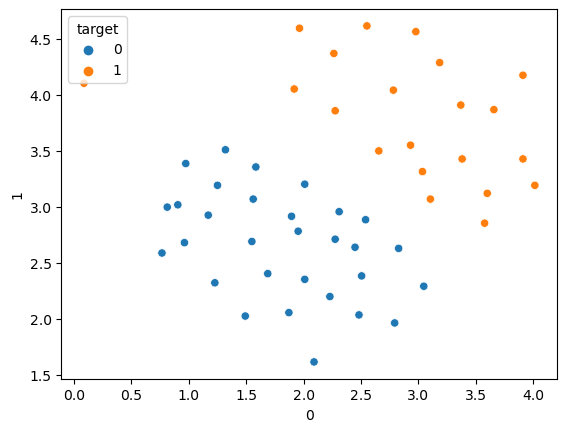

In [85]:
sns.scatterplot(x=df_dat1[0], y=df_dat1[1], hue=df_dat1['target']);

Notice that there is one outlier positive example that sits apart from the others.  The classes are still linearly separable but it's a very tight fit.  We're going to train a linear support vector machine to learn the class boundary.

#### 5. LinearSVC
Declare a Linear SVC with the hyperparamenters:

```Python
LinearSVC(C=1, loss='hinge', max_iter=10000)
```

In [86]:
from sklearn.svm import LinearSVC

In [87]:
from sklearn.preprocessing import StandardScaler

In [88]:
scaler = StandardScaler()
X_scal = scaler.fit_transform(dat1['X'])

In [89]:
svm_clf = LinearSVC(C = 1, loss='hinge', max_iter=10000)

In [90]:
svm_clf.fit(X_scal, dat1['y'].ravel())

c:\Users\julio\anaconda3\Lib\site-packages\sklearn\svm\_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(


LinearSVC(C=1, loss='hinge', max_iter=10000)

#### 6. Try the performance (score)
For the first experiment we'll use C=1 and see how it performs.

In [91]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

In [92]:
y_pred = svm_clf.predict(X_scal)

In [93]:
print(classification_report(dat1['y'], y_pred))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98        30
           1       1.00      0.95      0.98        21

    accuracy                           0.98        51
   macro avg       0.98      0.98      0.98        51
weighted avg       0.98      0.98      0.98        51



[[30  0]
 [ 1 20]]


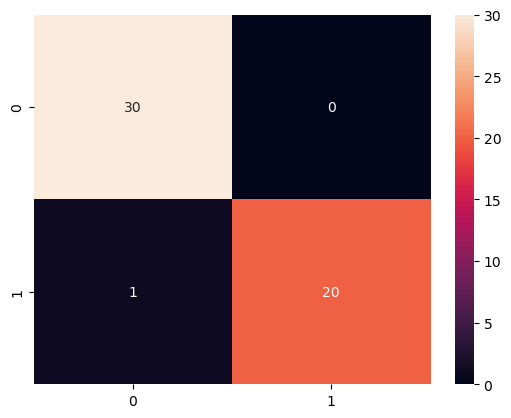

In [94]:
m_confu = confusion_matrix(dat1['y'], y_pred)
print(m_confu)
import seaborn as sns
sns.heatmap(m_confu, annot=True);

It appears that it mis-classified the outlier.

#### 7. Increase the value of C until you get a perfect classifier

In [95]:
svm_clf_2 = LinearSVC(C = 16, loss='hinge', max_iter=10000)
svm_clf_2.fit(X_scal, dat1['y'].ravel())
y_pred_2 = svm_clf_2.predict(X_scal)
print(classification_report(dat1['y'], y_pred_2))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        30
           1       1.00      1.00      1.00        21

    accuracy                           1.00        51
   macro avg       1.00      1.00      1.00        51
weighted avg       1.00      1.00      1.00        51



c:\Users\julio\anaconda3\Lib\site-packages\sklearn\svm\_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(


This time we got a perfect classification of the training data, however by increasing the value of C we've created a decision boundary that is no longer a natural fit for the data.  We can visualize this by looking at the confidence level for each class prediction, which is a function of the point's distance from the hyperplane.

#### 8. Plot Decission Function
Get the `decision_function()` output for the first model. Plot a scatterplot with X1, X2 and a range of colors based on `decision_function()`

In [96]:
dec_fun_1 = svm_clf.decision_function(X_scal)

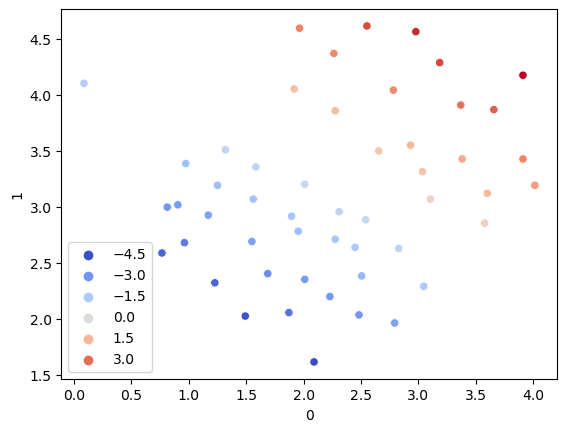

In [97]:
sns.scatterplot(x=df_dat1[0], y=df_dat1[1], hue=dec_fun_1, palette='coolwarm');

#### 9. Do the same with the second model

https://www.svm-tutorial.com/2015/06/svm-understanding-math-part-3/

In [98]:
dec_fun_2 = svm_clf_2.decision_function(X_scal)

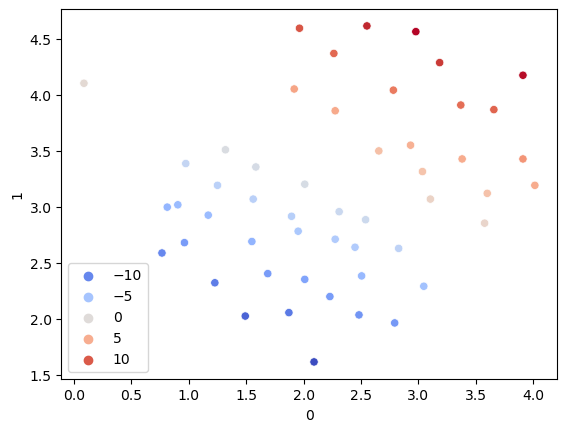

In [99]:
sns.scatterplot(x=df_dat1[0], y=df_dat1[1], hue=dec_fun_2, palette='coolwarm');

#### 1. Load the data `ejer_1_data2.mat`

In [100]:
dat2 = loadmat('data/ejer_1_data2.mat')

In [101]:
dat2.keys()

dict_keys(['__header__', '__version__', '__globals__', 'X', 'y'])

In [102]:
dat2['X'].shape

(863, 2)

In [103]:
dat2['X']

array([[0.107143 , 0.60307  ],
       [0.093318 , 0.649854 ],
       [0.0979263, 0.705409 ],
       ...,
       [0.975806 , 0.439474 ],
       [0.989631 , 0.425439 ],
       [0.996544 , 0.414912 ]])

In [104]:
dat2['y'].shape

(863, 1)

In [105]:
dat2['y']

array([[1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
    

#### 2. Create a DataFrame with the features and target

In [106]:
df_dat2 = pd.DataFrame(data=dat2['X'])
df_dat2['target'] = dat2['y']
df_dat2

,0,1,target
0,0.107143,0.603070,1
1,0.093318,0.649854,1
2,0.097926,0.705409,1
3,0.155530,0.784357,1
4,0.210829,0.866228,1
...,...,...,...
858,0.994240,0.516667,1
859,0.964286,0.472807,1
860,0.975806,0.439474,1
861,0.989631,0.425439,1


In [107]:
df_dat2['target'].value_counts()

target
1    480
0    383
Name: count, dtype: int64

#### 3. Plot a scatterplot with the data

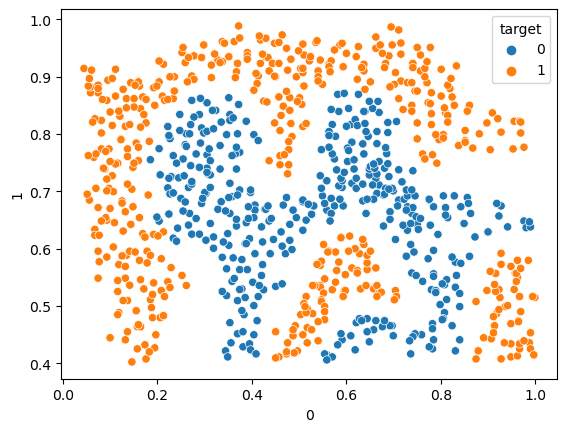

In [108]:
sns.scatterplot(x=df_dat2[0], y=df_dat2[1], hue=df_dat2['target']);

For this data set we'll build a support vector machine classifier using the built-in RBF kernel and examine its accuracy on the training data.  To visualize the decision boundary, this time we'll shade the points based on the predicted probability that the instance has a negative class label.  We'll see from the result that it gets most of them right.

#### 4. Declare a SVC with this hyperparameters
```Python
SVC(C=100, gamma=10, probability=True)
```


In [109]:
from sklearn.svm import SVC

In [110]:
svc_clf = SVC(C=100, gamma=10, probability=True)

#### 5. Fit the classifier and get the score

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       383
           1       1.00      1.00      1.00       480

    accuracy                           1.00       863
   macro avg       1.00      1.00      1.00       863
weighted avg       1.00      1.00      1.00       863

[[383   0]
 [  0 480]]


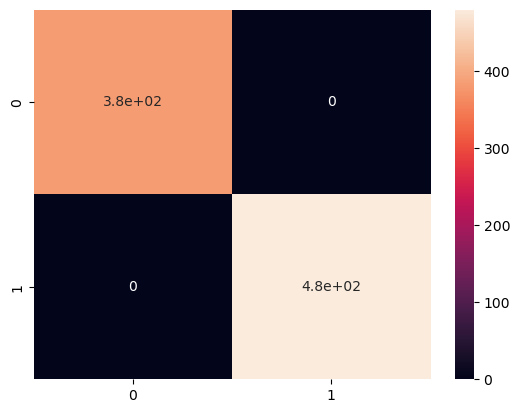

In [111]:
scaler2 = StandardScaler()
X2_scal = scaler2.fit_transform(dat2['X'])
svc_clf.fit(X2_scal, dat2['y'].ravel())
y2_pred = svc_clf.predict(X2_scal)
print(classification_report(dat2['y'], y2_pred))
m2_confu = confusion_matrix(dat2['y'], y2_pred)
print(m2_confu)
import seaborn as sns
sns.heatmap(m2_confu, annot=True);

#### 6. Plot the scatter plot and probability of predicting 0 with a [sequential color](https://matplotlib.org/3.1.1/tutorials/colors/colormaps.html)

In [112]:
# dec_fun_22 = svc_clf.decision_function(X2_scal)

In [113]:
pred_prob = svc_clf.predict_proba(X2_scal)

In [114]:
pred_prob[:,0].shape

(863,)

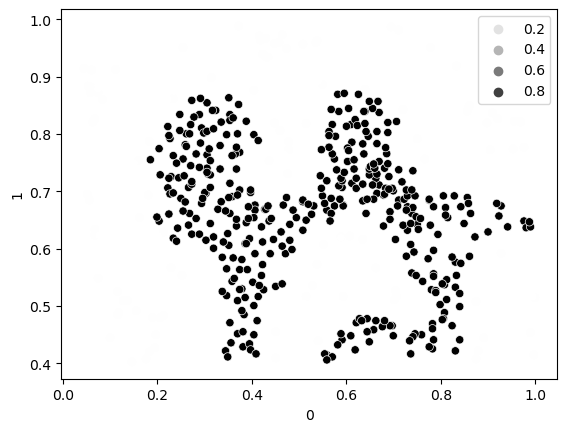

In [115]:
sns.scatterplot(x=df_dat2[0], y=df_dat2[1], hue=pred_prob[:,0], palette='Greys');